In [10]:
from pathlib import Path
from ultralytics import YOLO

base_dir = Path(r"C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03")
model_path = base_dir / "runs" / "detect" / "yolov8n_com_lixo" / "weights" / "best.pt"
images_dir = base_dir / "fotos"
output_dir = base_dir / "runs" / "teste03_predict"

print("base_dir existe:", base_dir.exists())
print("modelo existe:", model_path.exists())
print("fotos existe:", images_dir.exists())

# carrega o modelo treinado
model = YOLO(str(model_path))

# lista apenas imagens válidas
image_files = sorted(
    p for p in images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
)

print(f"Arquivos encontrados: {len(image_files)}")
for image_path in image_files:
    print(f"\nProcessando: {image_path.name}")

    results = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        project=str(output_dir),
        name="images_pred",
        exist_ok=True,
        save=True,
    )

    result = results[0]
    print(f"Detecções: {len(result.boxes)}")

    if len(result.boxes) > 0:
        for i, box in enumerate(result.boxes):
            cls = int(box.cls[0].item())
            conf = float(box.conf[0].item())
            xyxy = box.xyxy[0].tolist()
            print(f"  {i}: classe={cls} conf={conf:.3f} box={xyxy}")
    else:
        print("  Nenhuma detecção.")

base_dir existe: True
modelo existe: True
fotos existe: True
Arquivos encontrados: 5

Processando: 01941_06.jpg

image 1/1 C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\fotos\01941_06.jpg: 640x640 1 lixo, 177.4ms
Speed: 22.2ms preprocess, 177.4ms inference, 32.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\images_pred
Detecções: 1
  0: classe=0 conf=0.662 box=[2.4606082439422607, 367.286376953125, 127.87584686279297, 600.0]

Processando: 20260304_201319.jpg

image 1/1 C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\fotos\20260304_201319.jpg: 640x480 (no detections), 114.6ms
Speed: 19.7ms preprocess, 114.6ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\images_pred
Detecções: 0
  Nenhuma de

In [12]:
from PIL import Image
from pathlib import Path
from ultralytics import YOLO
from PIL import Image

base_dir = Path(r"C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03")
model = YOLO(str(base_dir / "runs" / "detect" / "yolov8n_com_lixo" / "weights" / "best.pt"))

output_dir = base_dir / "runs" / "teste03_predict" / "visualizados"
output_dir.mkdir(parents=True, exist_ok=True)

for image_path in sorted((base_dir / "fotos").iterdir()):
    if not image_path.is_file():
        continue
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}:
        continue

    results = model(image_path, imgsz=640, conf=0.25, verbose=False)
    result = results[0]

    annotated = result.plot()  # imagem com as caixas e rótulos
    out_path = output_dir / f"{image_path.stem}_detect.jpg"

    Image.fromarray(annotated[..., ::-1]).save(out_path)
    print(f"Salvo: {out_path}")
    print(f"Detecções: {len(result.boxes)}")

Salvo: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\visualizados\01941_06_detect.jpg
Detecções: 1
Salvo: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\visualizados\20260304_201319_detect.jpg
Detecções: 0
Salvo: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\visualizados\20260327_180118_detect.jpg
Detecções: 3
Salvo: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\visualizados\WhatsApp Image 2020-12-29 at 5.02.34 PM (3)_detect.jpg
Detecções: 1
Salvo: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\teste03_predict\visualizados\WhatsApp Image 2026-04-21 at 16.24.21_detect.jpg
Detecções: 0


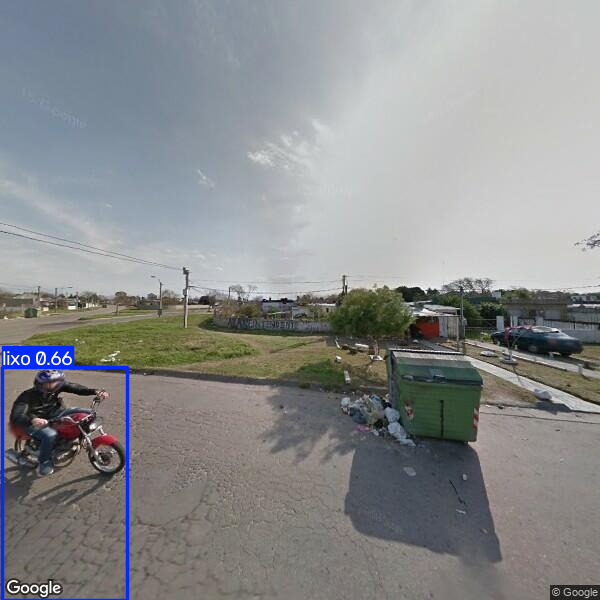

Imagem: 01941_06.jpg
Detecções: 1


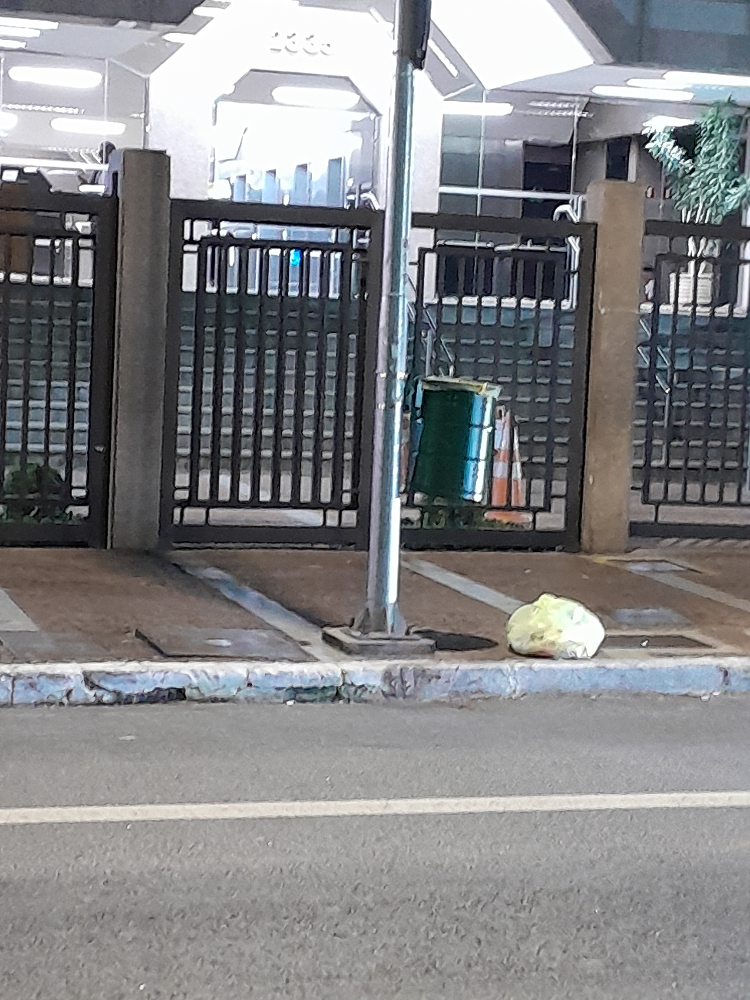

Imagem: 20260304_201319.jpg
Detecções: 0


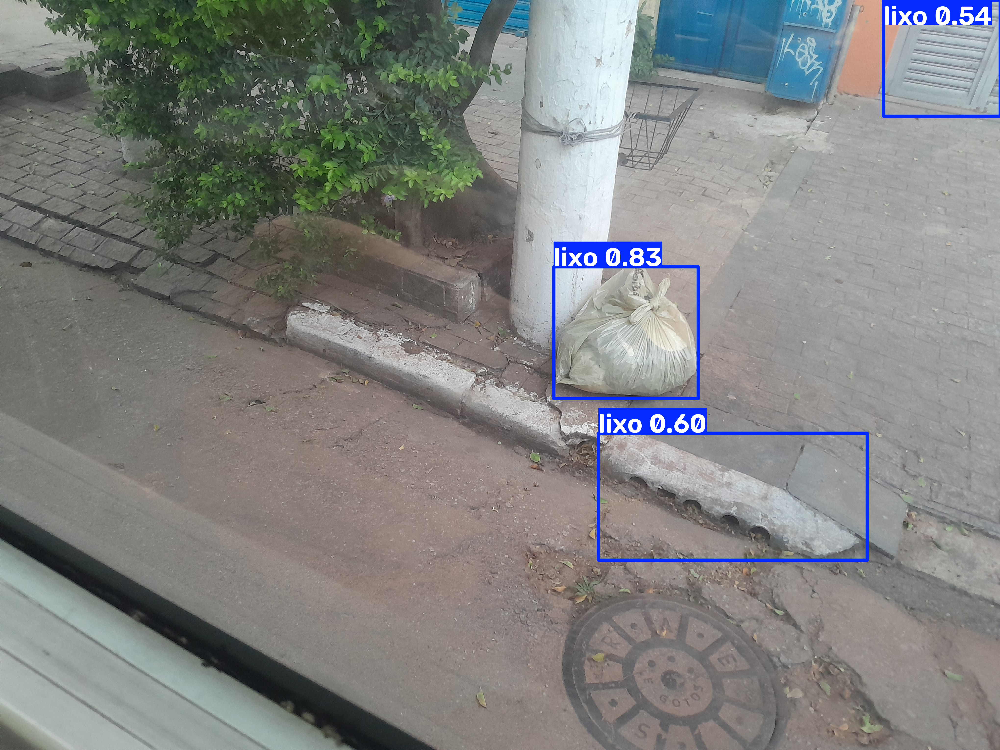

Imagem: 20260327_180118.jpg
Detecções: 3


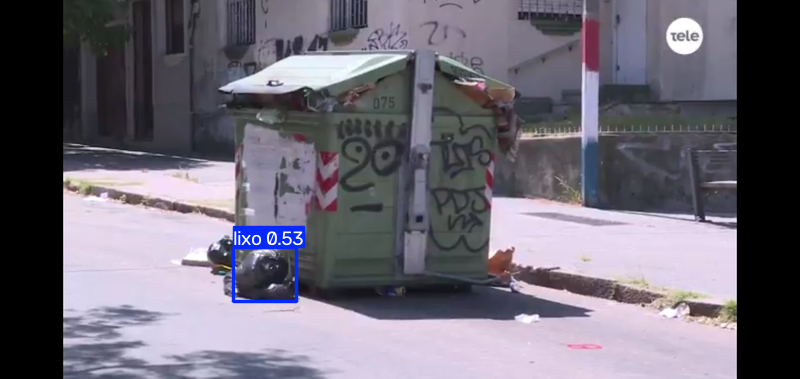

Imagem: WhatsApp Image 2020-12-29 at 5.02.34 PM (3).jpeg
Detecções: 1


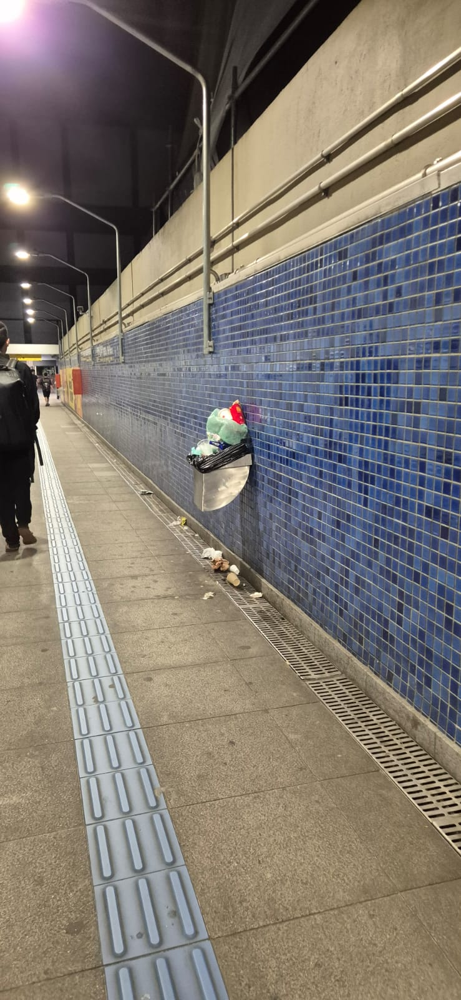

Imagem: WhatsApp Image 2026-04-21 at 16.24.21.jpeg
Detecções: 0


In [13]:
from IPython.display import display

for image_path in sorted((base_dir / "fotos").iterdir()):
    if not image_path.is_file():
        continue
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}:
        continue

    results = model(image_path, imgsz=640, conf=0.25, verbose=False)
    result = results[0]

    annotated = result.plot()[..., ::-1]
    display(Image.fromarray(annotated))
    print(f"Imagem: {image_path.name}")
    print(f"Detecções: {len(result.boxes)}")

In [ ]:
from ultralytics import YOLO
from pathlib import Path

base_dir = Path(r"C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03")
model = YOLO(str(base_dir / "runs" / "detect" / "teste03_lixo" / "weights" / "best.pt"))

print(model.names)

val_img = next((base_dir / "dataset_yolo" / "images" / "val").glob("*.*"))
foto = next((base_dir / "fotos").glob("*.*"))

for label, img in [("val", val_img), ("foto", foto)]:
    res = model(str(img), imgsz=640, conf=0.01, iou=0.3, verbose=False)
    print(label, "detecções:", len(res[0].boxes))

{0: 'lixo'}
val detecções: 26
foto detecções: 0


In [1]:
from pathlib import Path
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

base_dir = Path(r"C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03")
model = YOLO(str(base_dir / "runs" / "detect" / "teste03_lixo" / "weights" / "best.pt"))

fotos_dir = base_dir / "fotos"
image_paths = sorted(
    p for p in fotos_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
)

for img_path in image_paths:
    print(f"\nImagem: {img_path.name}")
    results = model(str(img_path), imgsz=640, conf=0.05, iou=0.3, verbose=False)
    result = results[0]

    print("Detecções:", len(result.boxes))

    if len(result.boxes) == 0:
        print("Nenhuma detecção nessa imagem.")
        continue

    # imagem anotada com caixas e labels
    img_annotated = result.plot()   # array no formato BGR
    img_rgb = img_annotated[..., ::-1]  # converte para RGB
    display(Image.fromarray(img_rgb))

    for i, box in enumerate(result.boxes):
        cls = int(box.cls[0].item())
        conf = float(box.conf[0].item())
        xyxy = box.xyxy[0].tolist()
        print(f"  {i}: classe={cls}, conf={conf:.3f}, bbox={xyxy}")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\alexa\\OneDrive\\Área de Trabalho\\TCC\\Teste Base de Imagens TCC 03\\runs\\detect\\teste03_lixo\\weights\\best.pt'

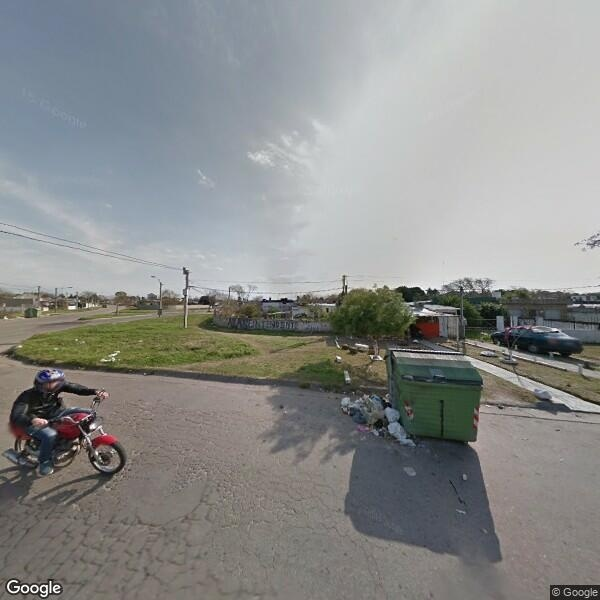

Detecções: 0


In [ ]:
img_path = base_dir / "fotos" / "01941_06.jpg"

results = model(str(img_path), imgsz=640, conf=0.05, iou=0.3, verbose=False)
result = results[0]
display(Image.fromarray(result.plot()[..., ::-1]))
print("Detecções:", len(result.boxes))